In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import ToTensor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

## Handling the dataset

In [2]:
# import datasets
training_data = datasets.MNIST(
    root="../data",
    train=True,
    download=False,
    transform=ToTensor() # scaling the pixel values from 0 -> 255 to 0 -> 1
)

print(len(training_data))

test_data = datasets.MNIST(
    root="../data",
    train=False,
    download=False,
    transform=ToTensor()
)

print(len(test_data))

60000
10000


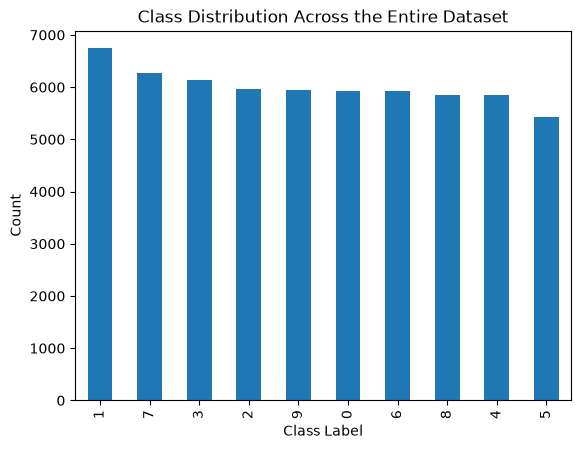

In [3]:
all_labels = []

for _, labels in training_data:
    all_labels.append(labels)

pd.Series(all_labels).value_counts().plot(kind="bar")
plt.title("Class Distribution Across the Entire Dataset")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

In [4]:
# This prints each digit and its exact count
counts = pd.Series(all_labels).value_counts()
print(counts)

1    6742
7    6265
3    6131
2    5958
9    5949
0    5923
6    5918
8    5851
4    5842
5    5421
Name: count, dtype: int64


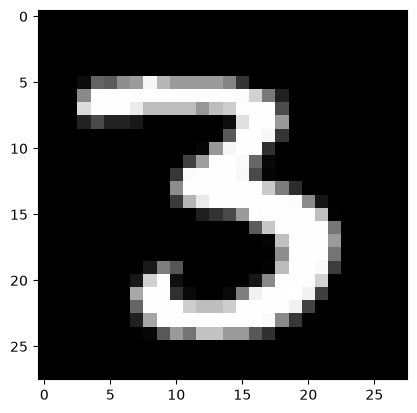

In [5]:
image_three, label_three = training_data[12]
image = image_three.unsqueeze(0)

plt.imshow(image.squeeze(), cmap="gray")
plt.show()

### Make the data for each client non-IID
- client1 - more data consisting of 0,1,2,3
- client2 - more data consisting of 4,5,6
- client3 - more data consisting of 7,8,9

Using **Dirichlet distribution**:
Dirichlet distribution is a standard method in machine learning, especially in Federated Learning (FL), to partition a centralized dataset into non-IID (non-independent and identically distributed) client splits

In [6]:
client1_train_data, client2_train_data, client3_train_data = random_split(
    training_data,
    [20000,20000,20000]
)

print(len(client1_train_data))
print(len(client2_train_data))
print(len(client3_train_data))

20000
20000
20000


In [7]:
client1_test_data, client2_test_data, client3_test_data = random_split(
    test_data,
    [3333,3333,3334]
)

print(len(client1_test_data))
print(len(client2_test_data))
print(len(client3_test_data))

3333
3333
3334


In [8]:
# dataloader
def create_dataloaders(train_data, test_data):
    train_data_loader = DataLoader(
        train_data,
        batch_size=64,
        shuffle=True
    )

    test_data_loader = DataLoader(
        test_data,
        batch_size=64,
        shuffle=True
    )

    return train_data_loader, test_data_loader

In [9]:
client1_train_loader, client1_test_loader = create_dataloaders (
    client1_train_data,
    client1_test_data
)

client2_train_loader, client2_test_loader = create_dataloaders (
    client2_train_data,
    client2_test_data
)

client3_train_loader, client3_test_loader = create_dataloaders (
    client3_train_data,
    client3_test_data
)

In [10]:
images, labels = next(iter(client1_train_loader))

print(images.shape)
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


In [11]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        
        # flatten layer
        # self.flatten = nn.flatten() # input [1,28,28] flattened input 1x28x28 = 784
        
        # define linear layers
        self.fcl1 = nn.Linear(784,128)
        self.fcl2 = nn.Linear(128,64)
        self.fcl3 = nn.Linear(64, 10)

    def forward(self,x):
        x = torch.flatten(x,1)
        x = F.relu(self.fcl1(x))
        x = F.relu(self.fcl2(x))
        x = self.fcl3(x)
        return x

### Minimal Federated learning model
without using flower 

Training each client, with a leanrning rate of 0.005 and Adam optimiser:
| Client   | Accuracy | Precison | Recall   | F1-score  | Loss      |
| -------- | -------- | -------- | -------- |  -------- |  -------- |
| Client 1 | 95.65%   |          |          |           |   0.16    |
| Client 2 | 95.34%   |          |          |           |   0.15    |
| Client 3 | 95.80%   |          |          |           |   0.14    | 


In [12]:
global_model = MLP()

client1_model = MLP()
client2_model = MLP()
client3_model = MLP()

In [13]:
# ensure the clients start with the same weights as the global model
client1_model.load_state_dict(global_model.state_dict())
client2_model.load_state_dict(global_model.state_dict())
client3_model.load_state_dict(global_model.state_dict())

<All keys matched successfully>

In [14]:
loss_function = nn.CrossEntropyLoss() 

# define each models own optimiser 
client1_optimiser = optim.Adam(
    client1_model.parameters(), 
    lr=0.005
)

client2_optimiser = optim.Adam(
    client2_model.parameters(), 
    lr=0.005
)

client3_optimiser = optim.Adam(
    client3_model.parameters(), 
    lr=0.005
)

In [15]:
def train_client(epochs, client, loader, loss_function, optimiser, model):
    for epoch in range(epochs):
        print(f"{client}: Starting training for epoch {epoch} ...")
    
        running_loss = 0.0
    
        for index, data in enumerate(loader):
            inputs, label = data
    
            optimiser.zero_grad()
            
            outputs = model(inputs)
    
            loss = loss_function(outputs, label)
            loss.backward()
            optimiser.step()
    
            running_loss += loss.item()
    
        print(f'{client}:Loss: {running_loss / len(loader):.4f}')
    return model
        
    #torch.save(model.state_dict(), f'trained_{client}_mlp.pth')

In [16]:
client1_model = train_client(3, "client 1", client1_train_loader, loss_function, client1_optimiser, client1_model)

client 1: Starting training for epoch 0 ...
client 1:Loss: 0.3809
client 1: Starting training for epoch 1 ...
client 1:Loss: 0.1583
client 1: Starting training for epoch 2 ...
client 1:Loss: 0.1189


In [17]:
client2_model = train_client(3, "client 2", client2_train_loader, loss_function, client2_optimiser, client2_model)

client 2: Starting training for epoch 0 ...
client 2:Loss: 0.3688
client 2: Starting training for epoch 1 ...
client 2:Loss: 0.1547
client 2: Starting training for epoch 2 ...
client 2:Loss: 0.1091


In [18]:
client3_model = train_client(3, "client 3", client3_train_loader, loss_function, client3_optimiser, client3_model)

client 3: Starting training for epoch 0 ...
client 3:Loss: 0.3800
client 3: Starting training for epoch 1 ...
client 3:Loss: 0.1589
client 3: Starting training for epoch 2 ...
client 3:Loss: 0.1130


In [19]:
def test_client(client, model, loader):
    
    model.eval()

    # test the model
    correct = 0
    running_loss = 0
    total = 0

    all_labels, all_predicted = [], []
    
    with torch.no_grad():
        for index, data in enumerate(loader):
            inputs, label = data
    
            outputs = model(inputs)
    
            _, predicted = torch.max(outputs, 1)
            total += label.size(0)

            loss = loss_function(outputs, label)
            running_loss += loss.item()
            
            correct += (predicted == label).sum().item()

            all_predicted.extend(predicted)
            all_labels.extend(label)
            
    
    accuracy = 100* correct / total
    average_loss = running_loss / len(loader)
    
    print(f'{client} test accuracy: {accuracy}%')
    print(f'{client} test loss: {average_loss}')
    return accuracy, all_labels, all_predicted

In [20]:
def evaluate_client(client, y_true, y_pred):
    cr = classification_report(y_true, y_pred)
    print(f"{client} classification report")
    print("\n",cr)

    cm = confusion_matrix(y_true, y_pred)
    display_cm = ConfusionMatrixDisplay(confusion_matrix=cm)
    display_cm.plot()

    plt.show()
    
    

### Client 1

In [21]:
# c1 - client 1
c1_test_acc, c1_y_true, c1_y_pred = test_client("client 1", client1_model, client1_test_loader)

client 1 test accuracy: 95.97959795979598%
client 1 test loss: 0.13004583324182709


cleint 1 classification report

               precision    recall  f1-score   support

           0       0.96      0.99      0.97       337
           1       0.99      0.97      0.98       391
           2       0.96      0.94      0.95       343
           3       0.94      0.99      0.96       341
           4       0.97      0.97      0.97       333
           5       0.95      0.94      0.94       293
           6       0.98      0.95      0.96       325
           7       0.96      0.96      0.96       343
           8       0.91      0.96      0.94       299
           9       0.96      0.93      0.95       328

    accuracy                           0.96      3333
   macro avg       0.96      0.96      0.96      3333
weighted avg       0.96      0.96      0.96      3333



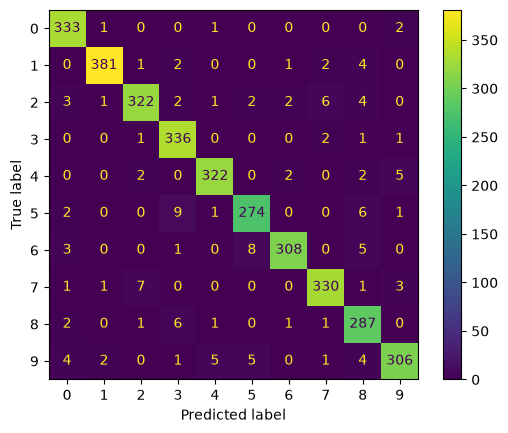

In [22]:
evaluate_c1 = evaluate_client("cleint 1", c1_y_true, c1_y_pred)

### Client 2

In [23]:
c2_test, c2_y_true, c2_y_pred = test_client("client 2", client2_model, client2_test_loader)

client 2 test accuracy: 95.22952295229523%
client 2 test loss: 0.16058855264816643


cleint 2 classification report

               precision    recall  f1-score   support

           0       0.96      0.99      0.98       326
           1       0.98      0.99      0.98       388
           2       0.92      0.95      0.93       345
           3       0.96      0.95      0.95       336
           4       0.91      0.98      0.94       336
           5       0.93      0.96      0.94       295
           6       0.99      0.93      0.96       304
           7       0.94      0.97      0.96       324
           8       0.97      0.89      0.93       330
           9       0.97      0.91      0.94       349

    accuracy                           0.95      3333
   macro avg       0.95      0.95      0.95      3333
weighted avg       0.95      0.95      0.95      3333



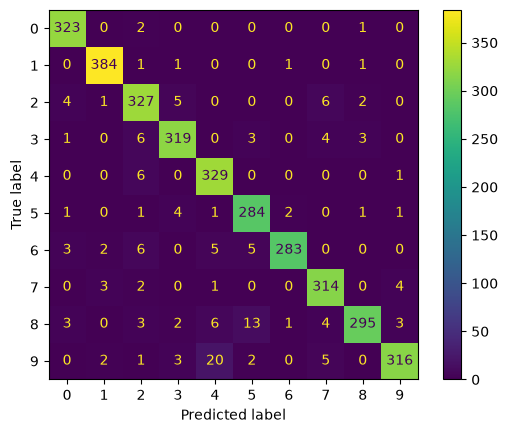

In [24]:
evaluate_c2 = evaluate_client("cleint 2", c2_y_true, c2_y_pred)

### Client 3

In [25]:
client3_test, c3_y_true, c3_y_pred = test_client("client 3", client3_model, client3_test_loader)

client 3 test accuracy: 95.20095980803839%
client 3 test loss: 0.1565972210593381


client 3 classification report

               precision    recall  f1-score   support

           0       0.99      0.99      0.99       317
           1       0.99      0.99      0.99       356
           2       0.99      0.94      0.96       344
           3       0.91      0.98      0.94       333
           4       0.99      0.89      0.94       313
           5       0.97      0.93      0.95       304
           6       0.93      0.98      0.95       329
           7       0.96      0.94      0.95       361
           8       0.97      0.90      0.93       345
           9       0.85      0.99      0.91       332

    accuracy                           0.95      3334
   macro avg       0.95      0.95      0.95      3334
weighted avg       0.95      0.95      0.95      3334



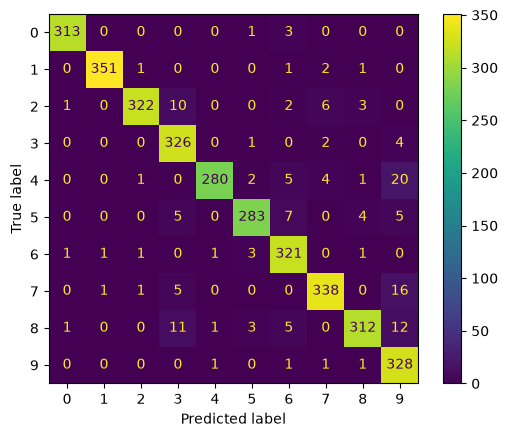

In [26]:
evaluate_c3 = evaluate_client("client 3", c3_y_true, c3_y_pred)